# Movie Recommender System with Collaborative Filtering

## Problem Definition

Given a sparse set of user ratings for movies, **predict the ratings users would give to movies they have not rated yet**, and use those predictions to:

1. Recommend movies to a user based on their taste.
2. Find movies similar to a given movie.

## Dataset

**MovieLens 20M** (GroupLens): about 20 million ratings, from 0.5 to 5.0 stars, given by about 138k users to about 27k movies.

Because the full user-movie matrix is too large to hold densely in memory, I build a smaller, denser subset:

- Keep users with at least 30 ratings, then randomly sample up to 20,000 of them.
- Keep movies with at least 100 ratings among the sampled users.
- Drop users left with fewer than 20 ratings.

Result: about **3.2M ratings**, about **20,000 users** and **4,255 movies**. Only a few percent of the matrix is observed, so this is a sparse-data problem.

## Approach: Matrix Factorization

Each movie `i` gets a feature vector `x_i` and each user `j` gets a taste vector `w_j` and a bias `b_j`. The predicted rating is:

$$\hat{y}_{ij} = x_i \cdot w_j + b_j$$

The parameters are learned by minimizing squared error over the **observed ratings only**, plus L2 regularization to prevent overfitting:

$$J = \frac{1}{2}\sum_{(i,j):\,r(i,j)=1}\left(x_i \cdot w_j + b_j - y_{ij}\right)^2 + \frac{\lambda}{2}\left(\sum_i \lVert x_i\rVert^2 + \sum_j \lVert w_j\rVert^2\right)$$

where `r(i,j) = 1` if user `j` rated movie `i`, and 0 otherwise. The model is trained with the Adam optimizer in PyTorch.

## Evaluation

- **Split:** 80% of the observed ratings for training and 20% held out for testing (random mask).
- **Metric:** RMSE on the held-out ratings (lower is better). Predictions are clipped to [0.5, 5].
- **Result:** test RMSE of about **0.80** with `n_features=30` and `lambda=10`.

## Applications

1. **Similar movies:** cosine similarity between learned movie vectors `x_i`.
2. **New-user recommendations (cold start):** keep the movie vectors frozen, then fit the new user's `w` and `b` from their ratings with ridge regression. Predict ratings for all other movies and recommend the top ones.

## Known Limitations and Future Work

- No global mean or per-movie bias term yet. Adding both should lower RMSE.
- Training had not fully converged, so a lower or decaying learning rate with more epochs should help.
- Recommendations are biased toward generally popular, highly rated movies, especially when a new user gives only high ratings.
- Movies with few ratings have unreliable vectors and are excluded from results.

In [1]:
import torch
import pandas as pd
import numpy as np
# setting seeds
np.random.seed(42)
torch.manual_seed(42)
# set device
device="cuda" if torch.cuda.is_available()else"cpu"

# Data preprocessing

In [2]:
df=pd.read_csv("/kaggle/input/datasets/grouplens/movielens-20m-dataset/rating.csv")

In [3]:
df.shape

(20000263, 4)

In [4]:
df.sample(10)

,userId,movieId,rating,timestamp
17679788,122270,8360,3.5,2012-04-22 01:07:04
7106385,49018,32,2.0,2001-09-11 07:50:36
12970708,89527,109374,3.5,2015-01-06 09:26:40
15426752,106704,1060,3.0,2000-01-22 21:27:57
6934678,47791,1732,2.0,2006-01-19 15:48:23
1672921,11304,504,1.0,2003-05-01 17:20:18
7224086,49851,1792,2.5,2003-08-04 02:41:55
5912488,40721,32213,4.0,2015-02-01 01:01:04
19670297,136187,1816,2.0,2003-03-08 21:41:32
19116402,132231,3996,5.0,2003-08-04 18:40:10


In [5]:
movies=pd.read_csv("/kaggle/input/datasets/grouplens/movielens-20m-dataset/movie.csv")
movies['year'] = movies['title'].str.extract(r'\((\d{4})\)').astype(float)

In [63]:
movies = pd.read_csv("/kaggle/input/datasets/grouplens/movielens-20m-dataset/movie.csv")
movies["year"] = movies["title"].str.extract(r"\((\d{4})\)").astype(float)
print("Movies:", len(movies))

r = df  # all movies, no isin needed

# 1. keep reasonably active users, then sample a subset of them
uc = r["userId"].value_counts()
active_users = uc[uc >= 30].index
rng = np.random.default_rng(42)
users = rng.choice(active_users, size=min(20000, len(active_users)), replace=False)
r = r[r["userId"].isin(users)]

# 2. keep only movies with 100+ ratings (within the sampled users)
mc = r["movieId"].value_counts()
r = r[r["movieId"].isin(mc[mc >= 100].index)]

# 3. re-check users after the movie filter
uc = r["userId"].value_counts()
r = r[r["userId"].isin(uc[uc >= 20].index)]

print(r.shape, r["userId"].nunique(), r["movieId"].nunique())

matrix = r.pivot(index="movieId", columns="userId", values="rating")
matrix = matrix.sample(frac=1, random_state=42).reset_index(drop=True)

Movies: 27278
(3234245, 4) 19996 4255


In [64]:
matrix.shape

(4255, 19996)

In [65]:
Y=torch.tensor(matrix.fillna(0).to_numpy(),dtype=torch.float32);
R=(Y!=0).float()

In [66]:
# make masks for train and test sets
R_test=((torch.rand(Y.shape)<=0.2) &( R==1)).float()
R_train=R-R_test

# Traning model

In [108]:
n_movies=matrix.shape[0]
n_features=30
n_users=matrix.shape[1]

In [126]:
# initalize parameters W,X,b
X = (torch.randn(n_movies, n_features) * 0.01).requires_grad_()
W = (torch.randn(n_users, n_features) * 0.01).requires_grad_()
b = torch.zeros(1, n_users, requires_grad=True)
X.shape,W.shape,b.shape

(torch.Size([4255, 30]), torch.Size([19996, 30]), torch.Size([1, 19996]))

In [127]:
def Cost_Function(X,W,b,Y,R,lambda_):
    return  0.5*((((X@W.T+b)-Y)*R)**2).sum()+0.5*lambda_*((W**2).sum()+(X**2).sum())
      

In [128]:
def rmse(pred, Y, mask):
    err = (pred - Y)[mask.bool()]
    return err.pow(2).mean().sqrt().item()

In [129]:
optim=torch.optim.Adam([W,X,b],lr=0.1)

In [130]:
X.to(device)
W.to(device)
b.to(device)
R_train.to(device)
R_test.to(device)


tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        ...,
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]], device='cuda:0')

In [131]:
def train(n_epochs,X,W,b,Y,R_trian,R_test,lambda_):   
    Train_rmses=[]
    Test_rmses=[]
    for i in range(n_epochs):
        optim.zero_grad()
        Loss=Cost_Function(X,W,b,Y,R_train,lambda_)
        Loss.backward()
        optim.step()   
        with torch.no_grad():
            pred = (X @ W.T + b).clamp(0.5, 5)   
            train_rmse = rmse(pred, Y, R_train)
            test_rmse = rmse(pred, Y, R_test)
            Train_rmses.append(train_rmse)
            Test_rmses.append(test_rmse)
        if i%5==0:   
            print(f"epoch {i+1}: Loss:{Loss.item():.3f} | train_rmse :{train_rmse:.3f} | test_rmse :{test_rmse:.3f}")
    return Train_rmses,Test_rmses
        
        

In [132]:
Train_rmses,Test_rmses=train(50,X,W,b,Y,R_train,R_test,10)

epoch 1: Loss:17688962.000 | train_rmse :3.222 | test_rmse :3.221
epoch 6: Loss:2860666.000 | train_rmse :1.201 | test_rmse :1.198
epoch 11: Loss:1629596.625 | train_rmse :0.952 | test_rmse :0.981
epoch 16: Loss:2444536.000 | train_rmse :1.151 | test_rmse :1.187
epoch 21: Loss:1550699.625 | train_rmse :0.992 | test_rmse :1.010
epoch 26: Loss:1148384.875 | train_rmse :0.841 | test_rmse :0.886
epoch 31: Loss:1228829.500 | train_rmse :0.806 | test_rmse :0.856
epoch 36: Loss:1144919.625 | train_rmse :0.791 | test_rmse :0.839
epoch 41: Loss:1014533.875 | train_rmse :0.774 | test_rmse :0.831
epoch 46: Loss:978321.375 | train_rmse :0.732 | test_rmse :0.796


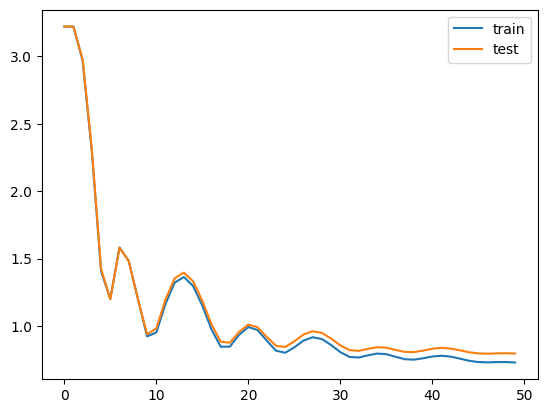

In [133]:
# plot curves 
import matplotlib.pyplot as plt
plt.plot(Train_rmses,label="train")
plt.plot(Test_rmses,label="test")
plt.legend()
plt.show()

# Test our model by getting the similar movies

In [134]:
import torch.nn.functional as F
import difflib

# 1. Recover row -> movieId (same pivot + same seeded shuffle as your notebook)
pivot = r.pivot(index="movieId", columns="userId", values="rating")
movie_ids = pivot.sample(frac=1, random_state=42).index.to_numpy()
assert len(movie_ids) == X.shape[0]          # sanity check

# 2. Row -> title
titles = pd.Series(movies.set_index("movieId").loc[movie_ids, "title"].values)

# 3. Normalized movie vectors + number of training ratings per movie
Xn = F.normalize(X.detach().cpu(), dim=1)
n_train = R_train.sum(1).cpu().numpy()

# 4. Search function
def similar_movies(query, k=10, min_ratings=20):
    matches = titles[titles.str.contains(query, case=False, regex=False)]
    if matches.empty:
        close = difflib.get_close_matches(query, titles.tolist(), n=5, cutoff=0.4)
        print(f"No match for '{query}'." + (f" Did you mean: {close}" if close else ""))
        return
    idx = matches.index[np.argmax(n_train[matches.index])]   # most-rated match
    if len(matches) > 1:
        print(f"{len(matches)} matches, using: {titles[idx]}")

    sims = Xn @ Xn[idx]
    sims[idx] = -2                                           # exclude itself
    sims[torch.from_numpy(n_train < min_ratings)] = -2       # skip weak vectors
    top = sims.topk(k)
    print(f"\nMovies similar to: {titles[idx]}")
    return pd.DataFrame({
        "title": titles.iloc[top.indices.numpy()].values,
        "similarity": top.values.numpy().round(3),
        "n_ratings": n_train[top.indices.numpy()].astype(int),
    })



In [141]:
similar_movies("Avengers")

2 matches, using: Avengers, The (2012)

Movies similar to: Avengers, The (2012)


,title,similarity,n_ratings
0,Captain America: The First Avenger (2011),0.957,362
1,Captain America: The Winter Soldier (2014),0.957,198
2,"Hunger Games, The (2012)",0.948,554
3,Iron Man 3 (2013),0.947,291
4,X-Men: Days of Future Past (2014),0.942,239
5,Iron Man 2 (2010),0.942,590
6,X-Men: First Class (2011),0.939,561
7,Sherlock Holmes: A Game of Shadows (2011),0.939,337
8,Super 8 (2011),0.938,265
9,Thor: The Dark World (2013),0.935,135


# Recommed some movies for me 

In [136]:
Xc = X.detach().cpu()

def find_movie(query):
    """Row index for a title: exact match first, else most-rated substring match, else None."""
    exact = titles[titles.str.lower() == query.lower()]
    if not exact.empty:
        return exact.index[0]
    m = titles[titles.str.contains(query, case=False, regex=False)]
    if m.empty:
        return None
    return m.index[np.argmax(n_train[m.index])]

def keep_available(ratings, verbose=True):
    ok = {}
    for name, rating in ratings.items():
        if find_movie(name) is None:
            if verbose:
                print("not in model, skipped:", name)
        else:
            ok[name] = rating
    return ok

def recommend_for_new_user(my_ratings, lambda_, k=10, min_ratings=100, verbose=False):
    # 1. map titles -> rows
    idx, y = [], []
    for name, rating in my_ratings.items():
        i = find_movie(name)
        if i is None:
            print("not in model, skipped:", name)
            continue
        if verbose:
            print(f"{name!r} -> {titles[i]}  (rating {rating})")
        idx.append(int(i)); y.append(rating)
    idx = torch.tensor(idx)
    y = torch.tensor(y, dtype=torch.float32)

    # 2. solve for [w, b] with X frozen (bias is not regularized, like your loss)
    A = torch.cat([Xc[idx], torch.ones(len(idx), 1)], dim=1)
    reg = torch.diag(torch.tensor([float(lambda_)] * Xc.shape[1] + [0.0]))
    theta = torch.linalg.solve(A.T @ A + reg, A.T @ y)
    w, b_new = theta[:-1], theta[-1]

    # 3. predict every movie; hide rated and weakly trained ones
    pred = (Xc @ w + b_new).clamp(0.5, 5)
    pred[idx] = -1
    pred[torch.from_numpy(n_train < min_ratings)] = -1
    top = pred.topk(k)

    return pd.DataFrame({
        "title": titles.iloc[top.indices.numpy()].values,
        "predicted_rating": top.values.numpy().round(2),
        "n_ratings": n_train[top.indices.numpy()].astype(int),
    })



In [142]:
# Example: a user who loves sci-fi/fantasy and dislikes romance
my_ratings = {
    # Sci-fi / fantasy
    "Lord of the Rings: The Fellowship of the Ring, The (2001)": 5.0,
    "Lord of the Rings: The Two Towers, The (2002)": 5.0,
    "Lord of the Rings: The Return of the King, The (2003)": 5.0,
    "Inception (2010)": 4.8,
    "Blade Runner (1982)": 3.5,
    "Interstellar (2014)": 5.0,
    "Back to the Future (1985)": 4.5,
    "Jurassic Park (1993)": 4.0,

    # Harry Potter (all 8)
    "Harry Potter and the Sorcerer's Stone": 5.0,
    "Harry Potter and the Chamber of Secrets": 5.0,
    "Harry Potter and the Prisoner of Azkaban": 5.0,
    "Harry Potter and the Goblet of Fire": 5.0,
    "Harry Potter and the Order of the Phoenix": 5.0,
    "Harry Potter and the Half-Blood Prince": 5.0,
    "Harry Potter and the Deathly Hallows: Part 1": 5.0,
    "Harry Potter and the Deathly Hallows: Part 2": 5.0,

    # Action / superhero / adventure
    "Dark Knight, The (2008)": 5.0,
    "Batman Begins (2005)": 4.5,
    "Iron Man (2008)": 4.5,
    "Avengers, The (2012)": 4.7,
    "Pirates of the Caribbean: The Curse of the Black Pearl (2003)": 4.5,
    "Gladiator (2000)": 4.7,
    "Saving Private Ryan (1998)": 4.9,

    # Spider-Man
    "Spider-Man (2002)": 4.3,
    "Spider-Man 2 (2004)": 4.6,
    "Spider-Man 3 (2007)": 3.3,
    "Amazing Spider-Man, The (2012)": 4.2,

    # Crime / drama classics
    "Fight Club (1999)": 5.0,
    "Pulp Fiction (1994)": 5.0,
    "Shawshank Redemption, The (1994)": 5.0,
    "Forrest Gump (1994)": 5.0,
    "Godfather, The (1972)": 5.0,
    "Silence of the Lambs, The (1991)": 5.0,
    "Se7en": 4.5,

    # Romance / drama
    "Titanic (1997)": 4.2,
    "Notebook, The (2004)": 4.5,
    "You've Got Mail (1998)": 4.7,
    "Eternal Sunshine of the Spotless Mind (2004)": 4.8,
    "Pride & Prejudice (2005)": 4.7,
    "(500) Days of Summer (2009)": 4.2,
    "Atonement (2007)": 3.9,
    "Fault in Our Stars, The (2014)": 4.5,
    "Devil Wears Prada, The (2006)": 4.4,

    # Animation
    "Toy Story (1995)": 5.0,
    "Toy Story 2 (1999)": 4.8,
    "Toy Story 3 (2010)": 4.9,
    "Finding Nemo (2003)": 5.0,
    "Lion King, The (1994)": 5.0,
    "Incredibles, The (2004)": 4.5,
    "Monsters, Inc. (2001)": 4.7,
    "Up (2009)": 5.0,
    "WALL·E (2008)": 4.9,
    "Ratatouille (2007)": 5.0,
    "How to Train Your Dragon (2010)": 4.6,
    "Kung Fu Panda (2008)": 4.7,
    "Tangled (2010)": 4.4,
    "Aladdin (1992)": 4.7,
    "Beauty and the Beast (1991)": 3.5,
    "Ice Age (2002)": 4.1,
    "Cars (2006)": 4.6,
    "Inside Out (2015)": 4.5,
    "Mulan (1998)": 4.0,
}

my_ratings = keep_available(my_ratings)
print(len(my_ratings), "ratings found in the model")



not in model, skipped: Fault in Our Stars, The (2014)
not in model, skipped: Inside Out (2015)
60 ratings found in the model


In [144]:
recommend_for_new_user(my_ratings, lambda_=10, k=15)

,title,predicted_rating,n_ratings
0,"Amelie (Fabuleux destin d'Amélie Poulain, Le) ...",4.81,3328
1,"Pianist, The (2002)",4.78,1426
2,Intouchables (2011),4.76,376
3,"Beautiful Mind, A (2001)",4.74,3037
4,Howl's Moving Castle (Hauru no ugoku shiro) (2...,4.74,801
5,Memento (2000),4.73,4353
6,"Departed, The (2006)",4.73,2017
7,Life Is Beautiful (La Vita è bella) (1997),4.72,2513
8,Big Fish (2003),4.72,1803
9,Dead Poets Society (1989),4.72,2977
